Name: Jess Choi  
Github Username: yulimjchoi  
USC ID: 9452440573 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score, KFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

## 1. Decision Trees as Interpretable Models

### (a) Obtain Data

In [2]:
columns = ["temperature", "nausea", "lumbar-pain", "urine-pushing", "micturition-pains", "burning-urethra", "bladder-inflammation", "nephritis"]
df1 = pd.read_csv("../data/diagnosis.data", sep="\t", header=None, names=columns, encoding="utf-16", decimal=",")

In [3]:
binary_columns = columns[1:]
for column in binary_columns:
    df1[column] = df1[column].map({"yes": 1, "no": 0})
df1.head()

,temperature,nausea,lumbar-pain,urine-pushing,micturition-pains,burning-urethra,bladder-inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


In [4]:
feature_1 = columns[:6]
target_1 = columns[6:]
X_df1 = df1[feature_1]
y_df1 = df1[target_1]

In [5]:
y_joint = y_df1["bladder-inflammation"].astype(str) + "_" + y_df1["nephritis"].astype(str)
joint_labels = {"0_0": "neither", "0_1": "nephritis only", "1_0": "bladder-inflammation only", "1_1": "both"}

I used the label powerset approach because the two diagnoses are not mutually exclusive and can occur together. All four label combinations appear in the data, so treating each combination as one class allows a single decision tree to represent the relationship between the two diagnoses.

### (b) Build a decision tree

In [6]:
tree = DecisionTreeClassifier(criterion="gini", random_state=42)
tree.fit(X_df1, y_joint)
print("training accuracy:", tree.score(X_df1, y_joint))
print("tree depth:", tree.get_depth())
print("number of leaves:", tree.get_n_leaves())

training accuracy: 1.0
tree depth: 4
number of leaves: 6


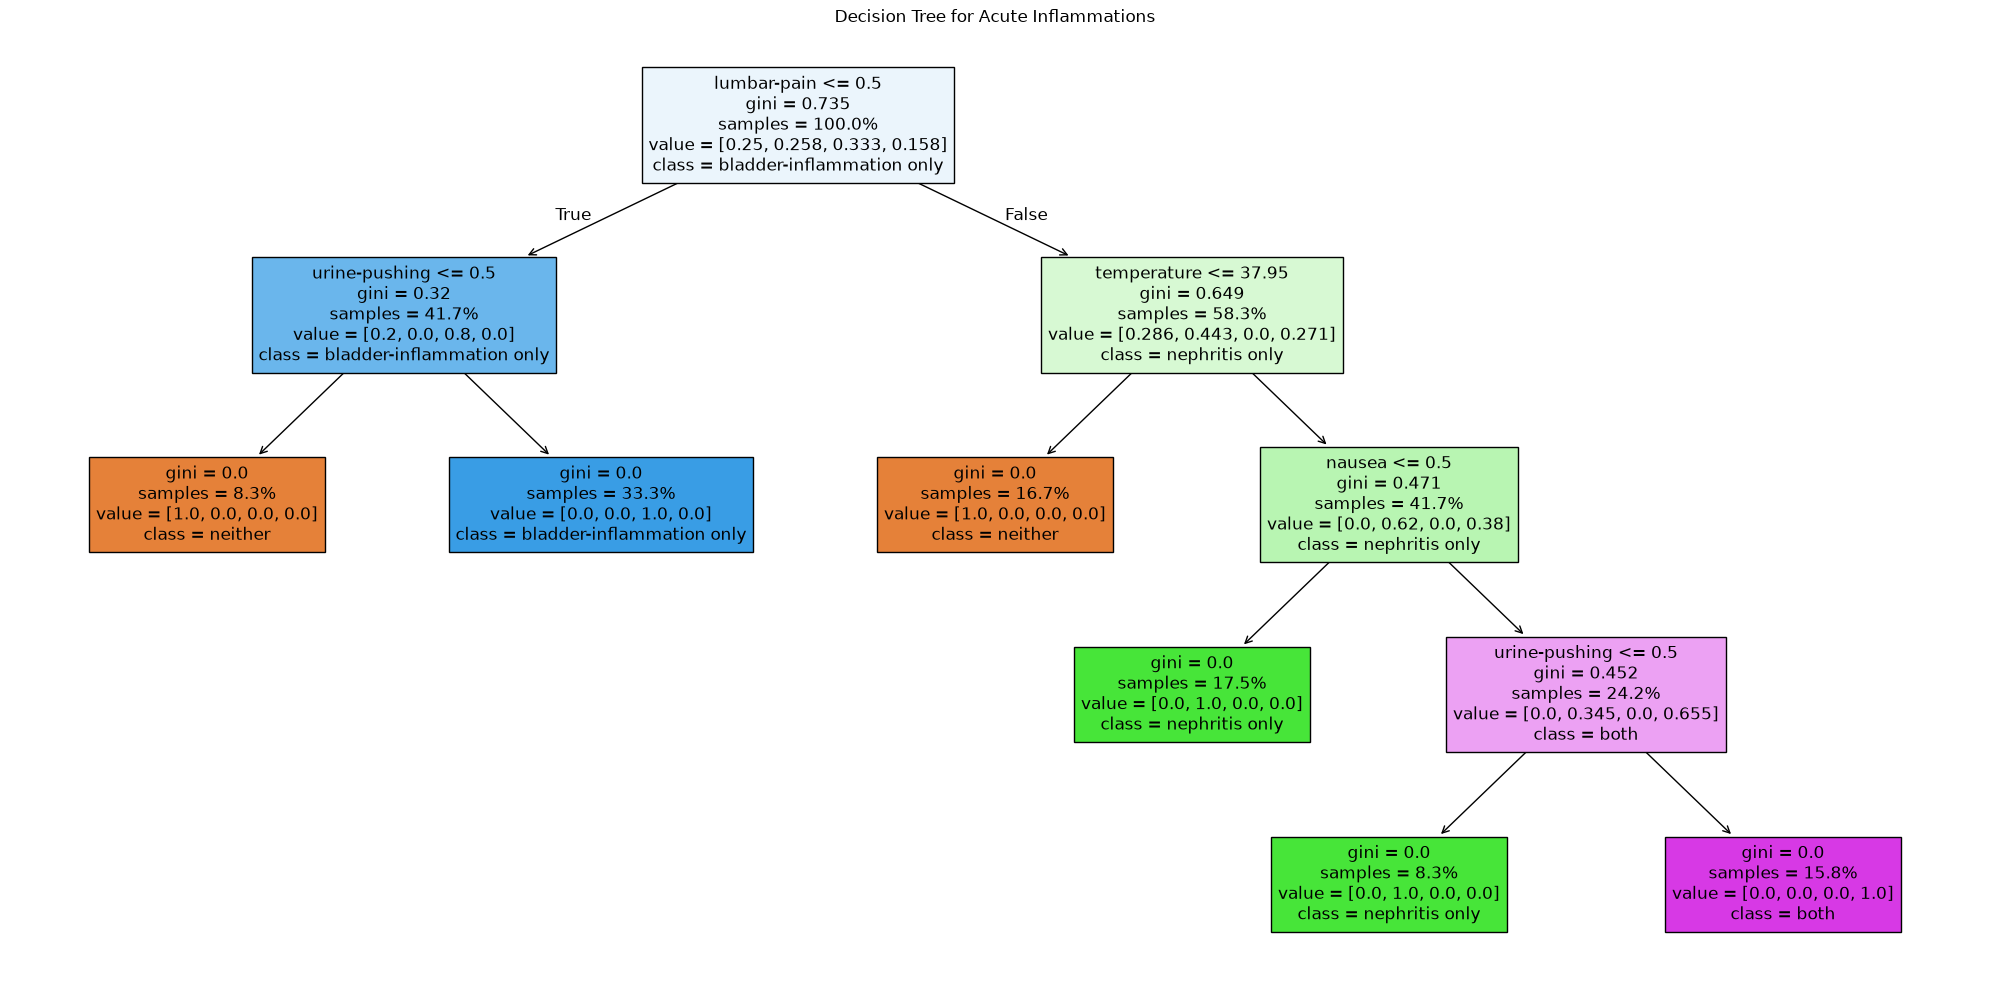

In [7]:
class_names_1 = [joint_labels[label] for label in tree.classes_]
plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=feature_1, class_names=class_names_1, filled=True, impurity=True, proportion=True)
plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [8]:
def tree_to_rules(tree, feature_names, label_names):
    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [feature_names[i] if i >= 0 else None for i in tree.tree_.feature]
    value = tree.tree_.value
    classes = tree.classes_

    def recurse(left, right, threshold, features, node, conditions):
        if threshold[node] != -2:
            feature = features[node]
            if left[node] != -1:
                left_condition = f"{feature} <= {threshold[node]:.2f}"
                recurse(left, right, threshold, features, left[node], conditions + [left_condition])
            if right[node] != -1:
                right_condition = f"{feature} > {threshold[node]:.2f}"
                recurse(left, right, threshold, features, right[node], conditions + [right_condition])
        else:
            class_index = value[node][0].argmax()
            predicted_class = label_names[classes[class_index]]
            print("IF " + " AND ".join(conditions) + " THEN " + predicted_class)

    recurse(left, right, threshold, features, 0, [])

In [9]:
tree_to_rules(tree, feature_1, joint_labels)

IF lumbar-pain <= 0.50 AND urine-pushing <= 0.50 THEN neither
IF lumbar-pain <= 0.50 AND urine-pushing > 0.50 THEN bladder-inflammation only
IF lumbar-pain > 0.50 AND temperature <= 37.95 THEN neither
IF lumbar-pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN nephritis only
IF lumbar-pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine-pushing <= 0.50 THEN nephritis only
IF lumbar-pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine-pushing > 0.50 THEN both


### (d) Pruning

In [10]:
path = tree.cost_complexity_pruning_path(X_df1, y_joint)
ccp_alphas = path.ccp_alphas

In [11]:
trees = []

for alpha in ccp_alphas:
    pruned_tree = DecisionTreeClassifier(criterion="gini", random_state=42, ccp_alpha=alpha)
    pruned_tree.fit(X_df1, y_joint)
    trees.append(pruned_tree)

In [12]:
pruning_results = pd.DataFrame({"ccp_alpha": ccp_alphas, 
                                "training_accuracy": [model.score(X_df1, y_joint) for model in trees], 
                                "depth": [model.get_depth() for model in trees], 
                                "leaves": [model.get_n_leaves() for model in trees]})

In [13]:
classification_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_accuracy = []

for model in trees:
    scores = cross_val_score(model, X_df1, y_joint, cv=classification_cv, scoring="accuracy")
    cv_accuracy.append(scores.mean())
pruning_results["cv_accuracy"] = cv_accuracy
pruning_results

,ccp_alpha,training_accuracy,depth,leaves,cv_accuracy
0,0.000000,1.000000,4,6,0.991667
1,0.098167,0.841667,2,4,0.858333
2,0.133333,0.758333,2,3,0.758333
3,0.182000,0.591667,1,2,0.666667
4,0.222917,0.333333,0,1,0.483333


In [14]:
pruned_candidates = pruning_results[pruning_results["ccp_alpha"] > 0]
selected_index = pruned_candidates["cv_accuracy"].idxmax()
selected_alpha = pruning_results.loc[selected_index, "ccp_alpha"]

Although the unpruned tree with ccp alpha equal to zero achieved the highest cross-validation accuracy, it did not remove any branches. Therefore, among the models with positive ccp alpha values, I selected the model with the highest cross-validation accuracy. The selected ccp alpha was approximately 0.098167. It reduced the tree depth from 4 to 2 and the number of leaves from 6 to 4. Its cross-validation accuracy was 0.8583, compared with 0.9917 for the unpruned tree. Therefore, the selected tree sacrifices some predictive accuracy in exchange for fewer and simpler decision rules.

In [15]:
minimal_tree = DecisionTreeClassifier(criterion="gini", random_state=42, ccp_alpha=selected_alpha)
minimal_tree.fit(X_df1, y_joint)
print("selected alpha:", selected_alpha)
print("training accuracy:", minimal_tree.score(X_df1, y_joint))
print("tree depth:", minimal_tree.get_depth())
print("number of leaves:", minimal_tree.get_n_leaves())

selected alpha: 0.09816666666666667
training accuracy: 0.8416666666666667
tree depth: 2
number of leaves: 4


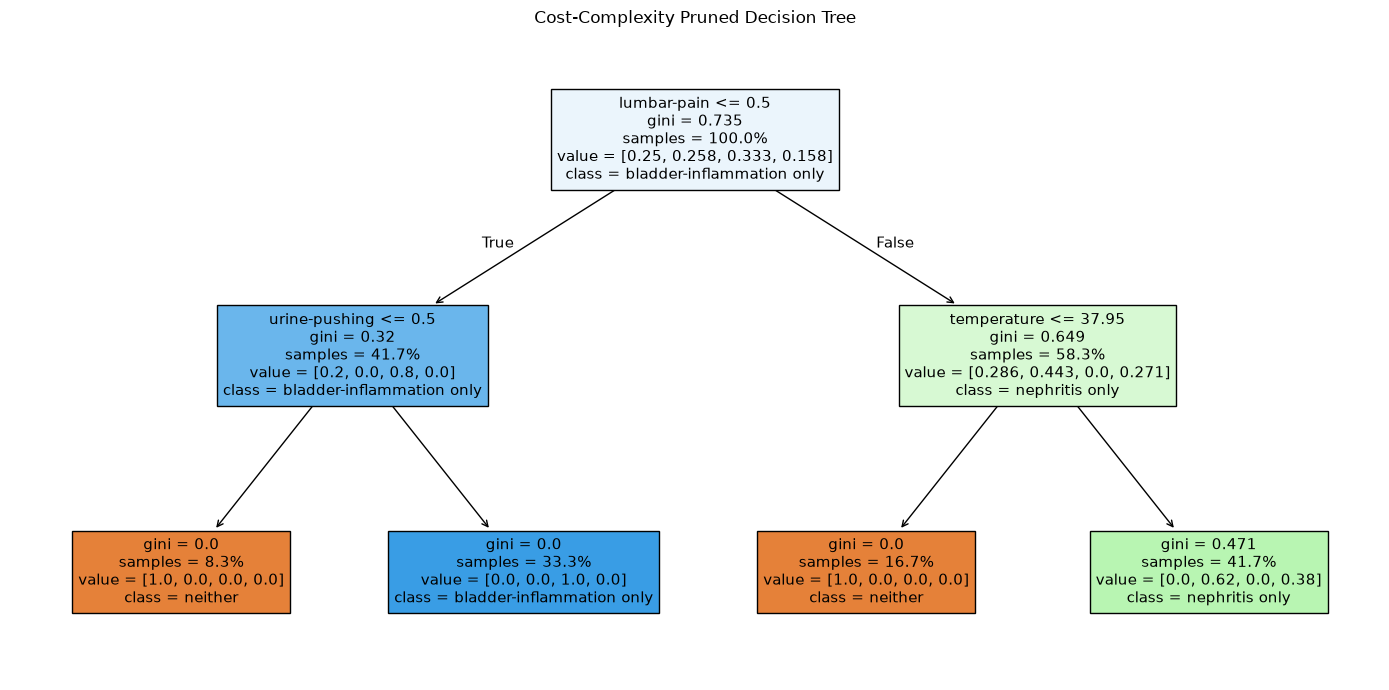

In [16]:
minimal_class_names = [joint_labels[label] for label in minimal_tree.classes_]
plt.figure(figsize=(14, 7))
plot_tree(minimal_tree, feature_names=feature_1, class_names=minimal_class_names, filled=True, impurity=True, proportion=True)
plt.title("Cost-Complexity Pruned Decision Tree")
plt.tight_layout()
plt.show()

In [17]:
tree_to_rules(minimal_tree, feature_1, joint_labels)

IF lumbar-pain <= 0.50 AND urine-pushing <= 0.50 THEN neither
IF lumbar-pain <= 0.50 AND urine-pushing > 0.50 THEN bladder-inflammation only
IF lumbar-pain > 0.50 AND temperature <= 37.95 THEN neither
IF lumbar-pain > 0.50 AND temperature > 37.95 THEN nephritis only


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [18]:
with open("../data/communities.names") as file:
    names_lines = file.readlines()

In [19]:
for line in names_lines:
    if "not predictive" in line.lower() or "not counted as predictive" in line.lower() or "goal attribute" in line.lower():
        print(line.strip())

-- state: US state (by number) - not counted as predictive above, but if considered, should be consided nominal (nominal)
-- county: numeric code for county - not predictive, and many missing values (numeric)
-- community: numeric code for community - not predictive and many missing values (numeric)
-- communityname: community name - not predictive - for information only (string)
-- fold: fold number for non-random 10 fold cross validation, potentially useful for debugging, paired tests - not predictive (numeric)
-- ViolentCrimesPerPop: total number of violent crimes per 100K popuation (numeric - decimal) GOAL attribute (to be predicted)


In [20]:
attribute_names = []

for line in names_lines:
    if line.strip().lower().startswith("@attribute"):
        attribute_names.append(line.split()[1])

len(attribute_names)

128

In [21]:
df2 = pd.read_csv("../data/communities.data", header=None, names=attribute_names, na_values="?")

In [22]:
train_df2 = df2.iloc[:1495].copy()
test_df2 = df2.iloc[1495:].copy()
print("training set:", train_df2.shape)
print("test set:", test_df2.shape)

training set: (1495, 128)
test set: (499, 128)


### (b) Missing values

In [23]:
non_predictive = ["state", "county", "community", "communityname", "fold"]
target_2 = "ViolentCrimesPerPop"

In [24]:
X_train = train_df2.drop(columns=non_predictive + [target_2])
y_train = train_df2[target_2]
X_test = test_df2.drop(columns=non_predictive + [target_2])
y_test = test_df2[target_2]
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1495, 122)
y_train: (1495,)
X_test: (499, 122)
y_test: (499,)


In [25]:
missing_values = X_train.isna().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print("features with missing values:", len(missing_values))
print("total missing values:", X_train.isna().sum().sum())

features with missing values: 23
total missing values: 27633


In [26]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

In [27]:
print("missing values in X_train:", X_train_imputed.isna().sum().sum())
print("missing values in X_test:", X_test_imputed.isna().sum().sum())

missing values in X_train: 0
missing values in X_test: 0


### (c) Plot a correlation matrix

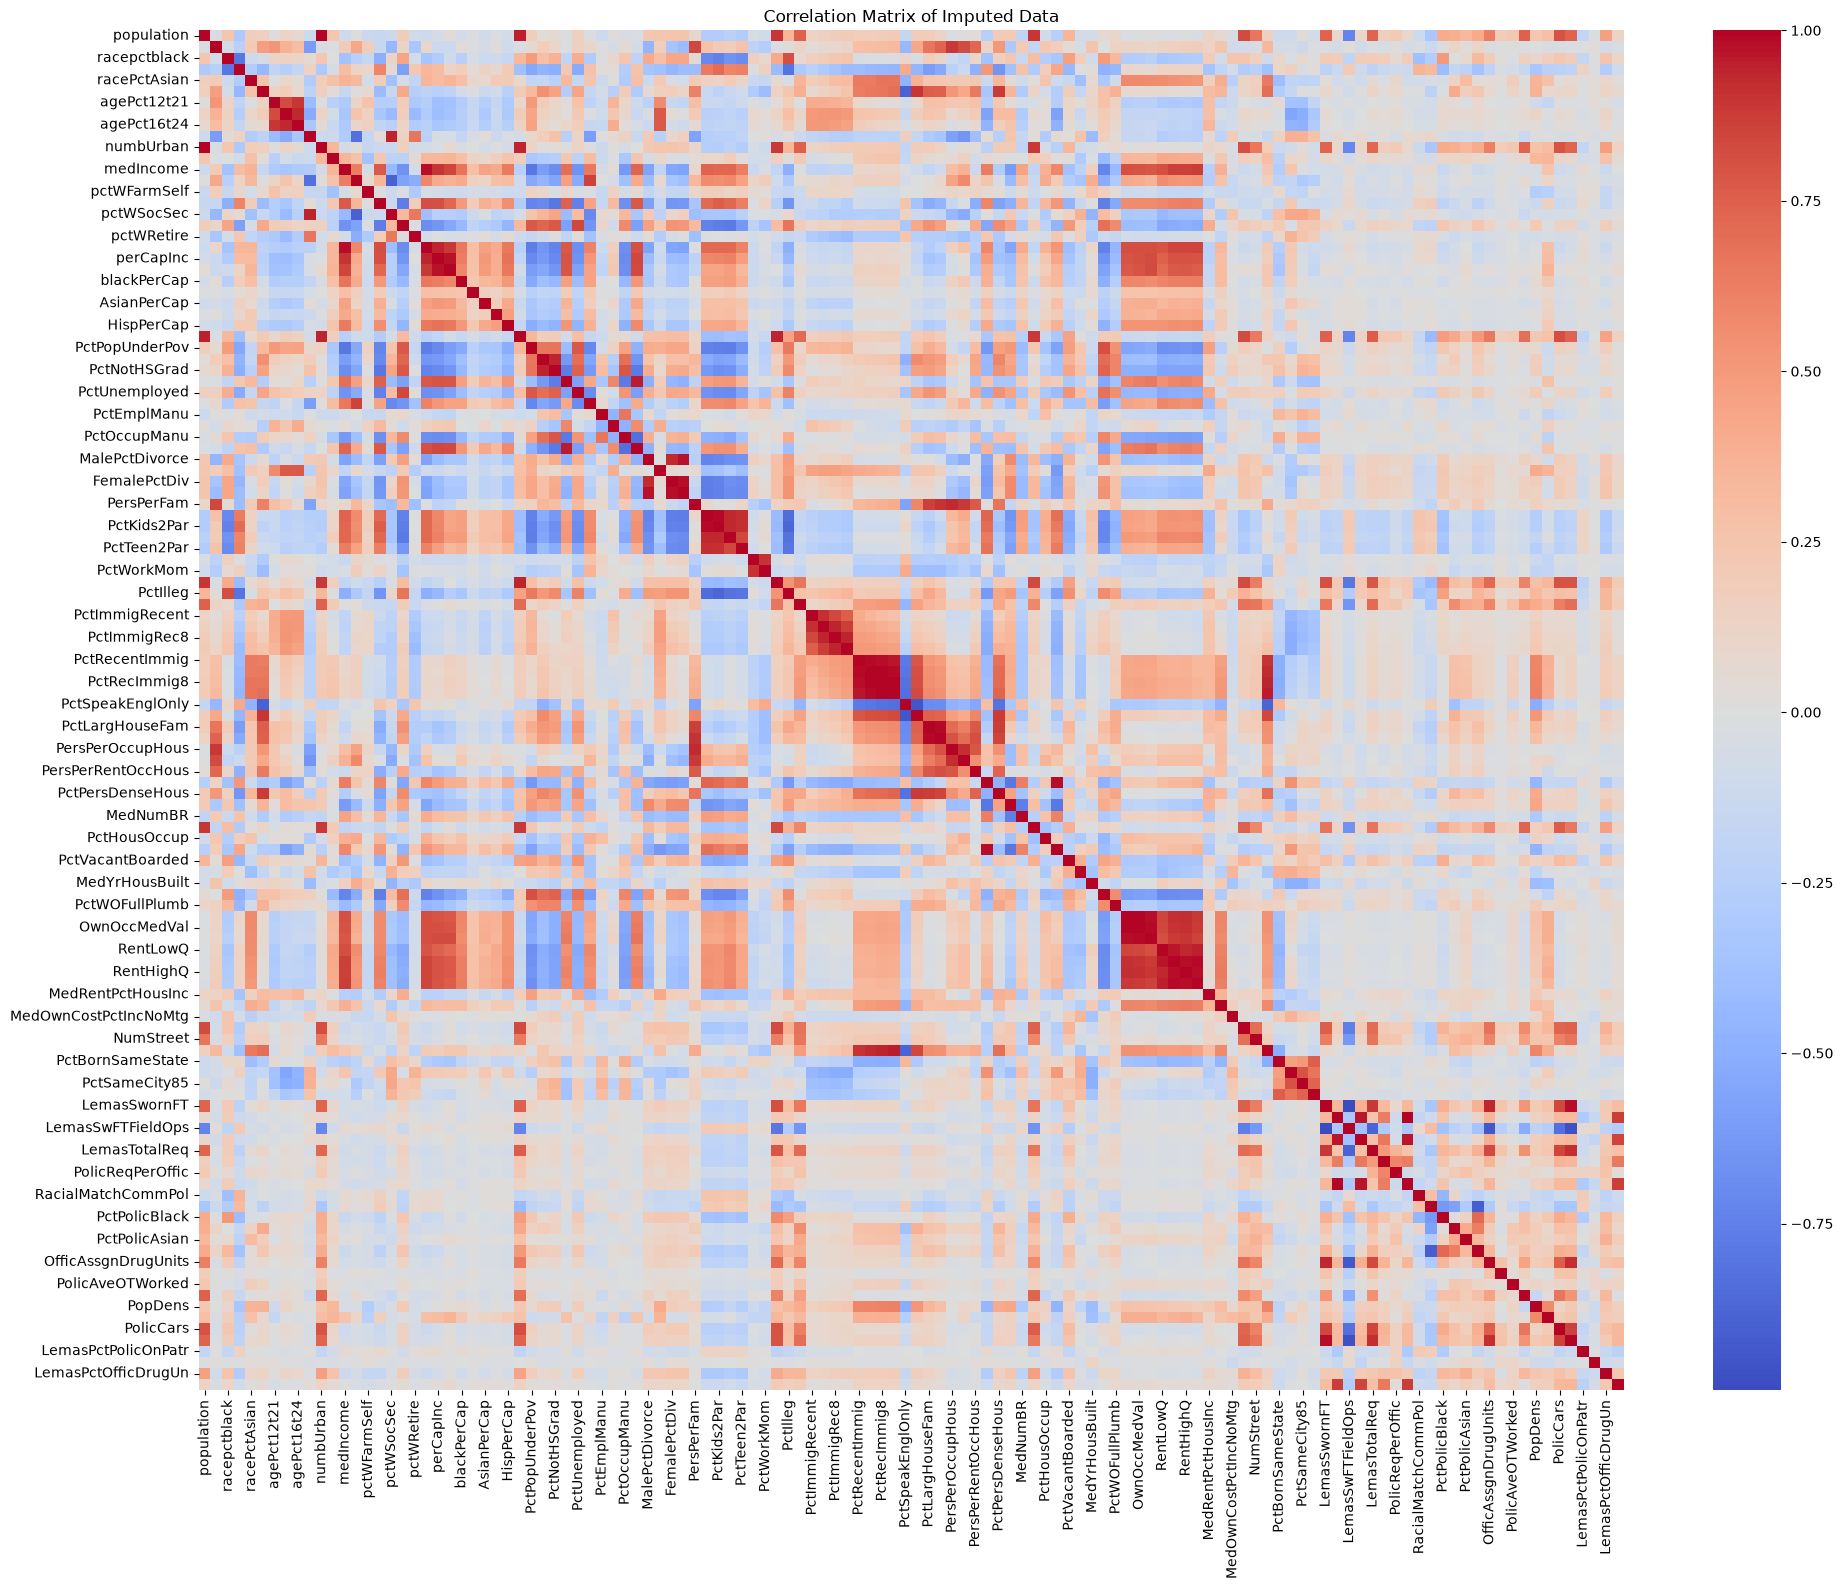

In [28]:
corr_matrix = X_train_imputed.corr()
plt.figure(figsize=(20, 16))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Imputed Data")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [29]:
feature_mean = X_train_imputed.mean()
feature_std = X_train_imputed.std(ddof=1)
coef_var = feature_std / feature_mean.replace(0, pd.NA)
cv_results = pd.DataFrame({"mean": feature_mean, "std": feature_std, "cv": coef_var}).sort_values("cv", ascending=False)
cv_results

,mean,std,cv
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727
LemasPctPolicOnPatr,0.752495,0.084304,0.112032


### (e) Scatter plots and box plots for highest CV features

In [30]:
number_of_features = int(np.floor(np.sqrt(128)))
top_cv_features = cv_results.head(number_of_features).index.tolist()
print("number of features:", number_of_features)
print("features with the highest CV:")
for feature in top_cv_features:
    print(feature)

number of features: 11
features with the highest CV:
PctPolicAsian
NumStreet
NumInShelters
NumIlleg
NumImmig
LemasPctOfficDrugUn
NumUnderPov
LemasSwornFT
population
numbUrban
HousVacant


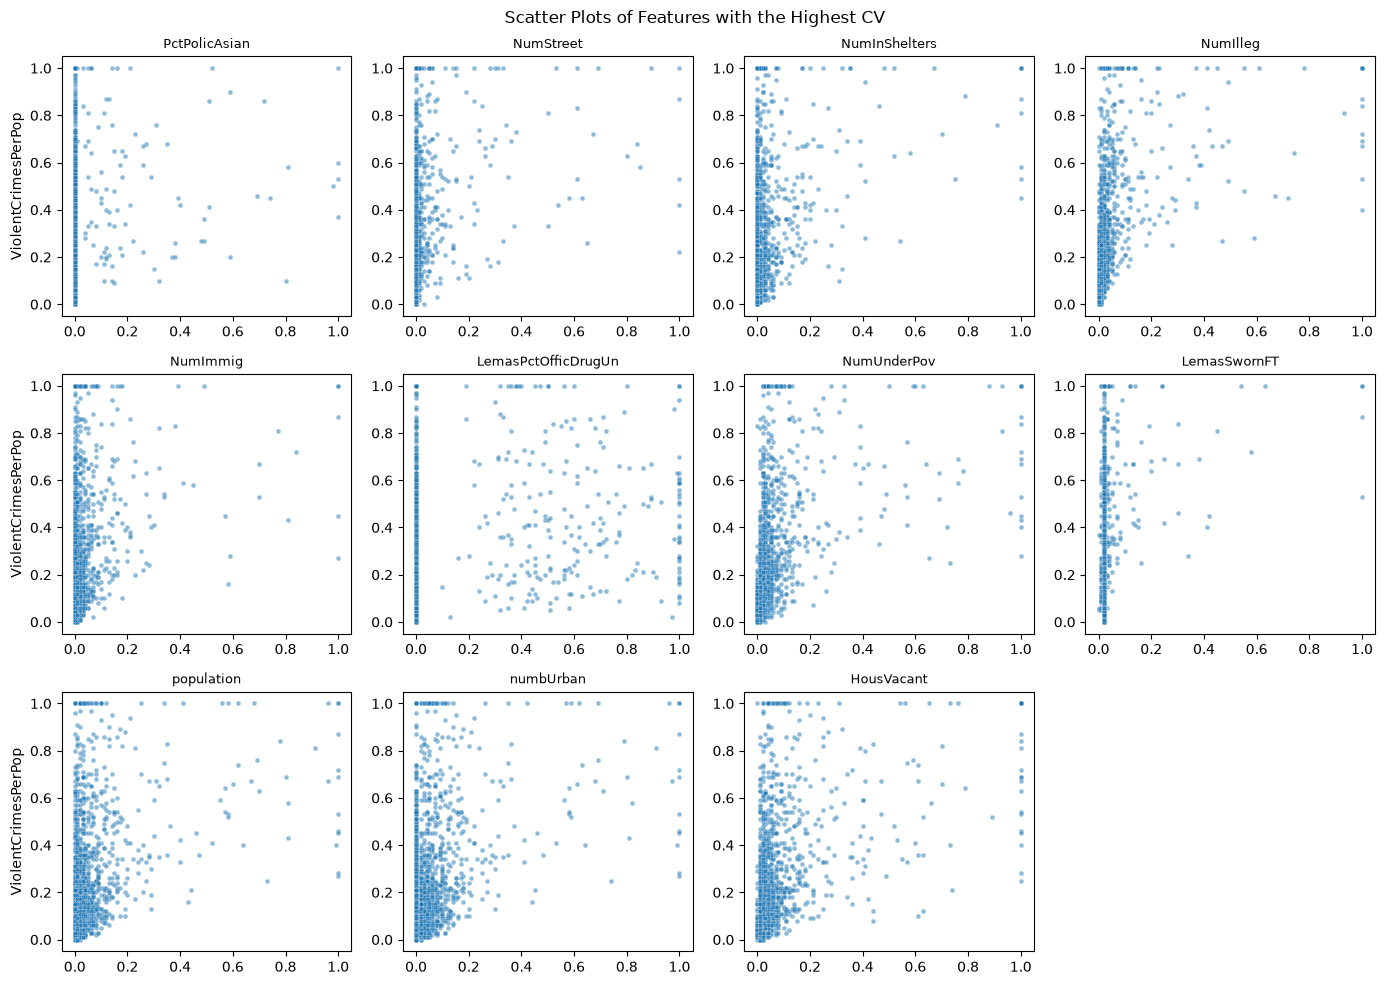

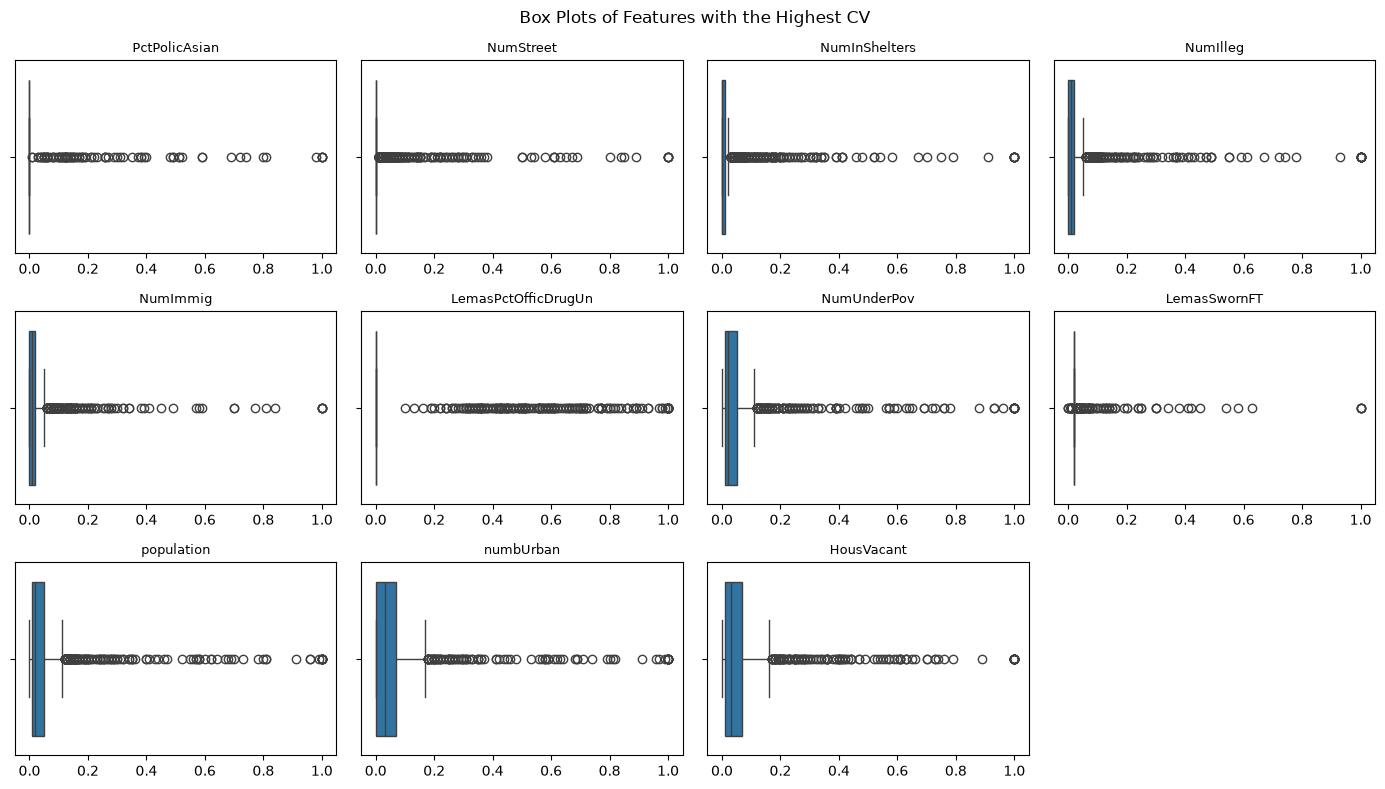

In [31]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(top_cv_features):
    sns.scatterplot(x=X_train_imputed[feature], y=y_train, ax=axes[i], s=12, alpha=0.5)
    axes[i].set_title(feature, fontsize=9)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("ViolentCrimesPerPop" if i % 4 == 0 else "")
for i in range(len(top_cv_features), len(axes)):
    axes[i].axis("off")
plt.suptitle("Scatter Plots of Features with the Highest CV")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(14, 8))
axes = axes.flatten()

for i, feature in enumerate(top_cv_features):
    sns.boxplot(x=X_train_imputed[feature], ax=axes[i])
    axes[i].set_title(feature, fontsize=9)
    axes[i].set_xlabel("")
for i in range(len(top_cv_features), len(axes)):
    axes[i].axis("off")
plt.suptitle("Box Plots of Features with the Highest CV")
plt.tight_layout()
plt.show()

The scatter plots show possible relationships between the selected features and ViolentCrimesPerPop, while the box plots show their distributions and potential outliers. However, the significance of these features cannot be determined from the plots alone. A high coefficient of variation only indicates high variability relative to the mean, and does not imply a strong relationship with the response. The method such as formal statistical analysis is needed to determine feature significance.

### (f) Fit a linear model

In [32]:
regression_cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [33]:
linear_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("linear", LinearRegression())])
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)
linear_test_mse = mean_squared_error(y_test, linear_predictions)
print("linear regression test MSE:", linear_test_mse)

linear regression test MSE: 0.01796621542606732


### (g) Fit a ridge regression model

In [34]:
ridge_model = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("ridge", Ridge())])
ridge_parameters = {"ridge__alpha": np.logspace(-4, 4, 100)}
ridge_search = GridSearchCV(
    ridge_model, param_grid=ridge_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
ridge_search.fit(X_train, y_train)
ridge_predictions = ridge_search.predict(X_test)
ridge_test_mse = mean_squared_error(y_test, ridge_predictions)
print("best ridge alpha:", ridge_search.best_params_["ridge__alpha"])
print("ridge test MSE:", ridge_test_mse)

best ridge alpha: 138.48863713938746
ridge test MSE: 0.01736038275948827


### (h) Fit a LASSO model

In [35]:
lasso_parameters = {"lasso__alpha": np.logspace(-5, 0, 100)}
lasso_model = Pipeline([("imputer", SimpleImputer(strategy="median")), ("lasso", Lasso(max_iter=100000))])
lasso_search = GridSearchCV(
    lasso_model, param_grid=lasso_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
lasso_search.fit(X_train, y_train)
lasso_predictions = lasso_search.predict(X_test)
lasso_test_mse = mean_squared_error(y_test, lasso_predictions)

In [36]:
lasso_coefficients = pd.Series(lasso_search.best_estimator_.named_steps["lasso"].coef_, index=X_train.columns)
lasso_selected = lasso_coefficients[lasso_coefficients.abs() > 1e-8].sort_values(key=np.abs, ascending=False)

def variable_table(selected_variables, number_of_columns=4):
    names = selected_variables.index.tolist()
    number_of_rows = int(np.ceil(len(names) / number_of_columns))
    names += [""] * (number_of_rows * number_of_columns - len(names))
    return pd.DataFrame(
        np.array(names).reshape(number_of_rows, number_of_columns), 
        columns=[f"Variable {i + 1}" for i in range(number_of_columns)])
print("number of selected variables:", len(lasso_selected))
variable_table(lasso_selected)

number of selected variables: 74


,Variable 1,Variable 2,Variable 3,Variable 4
0,racepctblack,agePct12t29,PctPersDenseHous,PctKids2Par
1,MedRent,RentLowQ,NumStreet,PctPopUnderPov
2,PctEmploy,MalePctNevMarr,PctWorkMom,HousVacant
3,MalePctDivorce,pctWRetire,pctWInvInc,PctIlleg
4,NumImmig,PolicReqPerOffic,MedRentPctHousInc,NumIlleg
5,pctWWage,FemalePctDiv,MedOwnCostPctIncNoMtg,PctNotSpeakEnglWell
6,PctVacantBoarded,LemasSwFTFieldPerPop,agePct12t21,PctLargHouseOccup
7,NumInShelters,PctHousOccup,PctVacMore6Mos,PctHousLess3BR
8,PctPersOwnOccup,whitePerCap,pctWSocSec,PctForeignBorn
9,PersPerOccupHous,PctUsePubTrans,pctUrban,pctWPubAsst


In [37]:
standardized_lasso_model = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), 
     ("scaler", StandardScaler()), 
     ("lasso", Lasso(max_iter=100000))])
standardized_lasso_search = GridSearchCV(
    standardized_lasso_model, param_grid=lasso_parameters, 
    scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
standardized_lasso_search.fit(X_train, y_train)
standardized_lasso_predictions = standardized_lasso_search.predict(X_test)
standardized_lasso_test_mse = mean_squared_error(y_test, standardized_lasso_predictions)

In [38]:
standardized_lasso_coeff = pd.Series(
    standardized_lasso_search.best_estimator_.named_steps["lasso"].coef_, index=X_train.columns)
standardized_lasso_selected = standardized_lasso_coeff[
    standardized_lasso_coeff.abs() > 1e-8].sort_values(key=np.abs, ascending=False)
print("number of selected variables:", len(standardized_lasso_selected))
variable_table(standardized_lasso_selected)

number of selected variables: 75


,Variable 1,Variable 2,Variable 3,Variable 4
0,racepctblack,PctPersDenseHous,agePct12t29,PctKids2Par
1,RentLowQ,MedRent,PctPopUnderPov,PctEmploy
2,PctIlleg,MalePctNevMarr,PctWorkMom,pctWInvInc
3,MalePctDivorce,pctWRetire,NumStreet,HousVacant
4,pctUrban,MedRentPctHousInc,PctVacantBoarded,MedOwnCostPctIncNoMtg
5,pctWWage,FemalePctDiv,PctNotSpeakEnglWell,agePct12t21
6,PctHousOccup,NumImmig,PctLargHouseOccup,PctPersOwnOccup
7,PctHousLess3BR,PctVacMore6Mos,pctWSocSec,NumIlleg
8,PolicReqPerOffic,PctUsePubTrans,whitePerCap,PctRecImmig10
9,NumInShelters,PersPerOccupHous,PctYoungKids2Par,PctForeignBorn


In [39]:
lasso_comparison = pd.DataFrame(
    {"model": ["LASSO", "Standardized LASSO"], 
     "best_alpha": [lasso_search.best_params_["lasso__alpha"], standardized_lasso_search.best_params_["lasso__alpha"]], 
     "selected_variables": [len(lasso_selected), len(standardized_lasso_selected)], 
     "test_MSE": [lasso_test_mse, standardized_lasso_test_mse]})
lasso_comparison

,model,best_alpha,selected_variables,test_MSE
0,LASSO,0.000115,74,0.017636
1,Standardized LASSO,0.000658,75,0.017714


The two LASSO models produced very similar test errors and selected nearly the same number of variables. The unstandardized model achieved a slightly lower test MSE. This small difference is reasonable because the original predictors were already normalized.

### (i) Fit a PCR model

In [40]:
pcr_model = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), 
     ("pca", PCA()), ("linear", LinearRegression())])
pcr_parameters = {"pca__n_components": np.arange(1, X_train.shape[1] + 1)}
pcr_search = GridSearchCV(
    pcr_model, param_grid=pcr_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
pcr_search.fit(X_train, y_train)
pcr_predictions = pcr_search.predict(X_test)
pcr_test_mse = mean_squared_error(y_test, pcr_predictions)
print("best number of components:", pcr_search.best_params_["pca__n_components"])
print("PCR test MSE:", pcr_test_mse)

best number of components: 60
PCR test MSE: 0.01834952528616995


### (j) Fit a boosting tree

In [41]:
xgboost_model = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), 
     ("xgboost", XGBRegressor(objective="reg:squarederror", n_estimators=500, learning_rate=0.05, max_depth=3, 
                              subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=42, n_jobs=1))])
xgboost_parameters = {"xgboost__reg_alpha": [0, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}
xgboost_search = GridSearchCV(
    xgboost_model, param_grid=xgboost_parameters, scoring="neg_mean_squared_error", cv=regression_cv, n_jobs=-1)
xgboost_search.fit(X_train, y_train)
xgboost_predictions = xgboost_search.predict(X_test)
xgboost_test_mse = mean_squared_error(y_test, xgboost_predictions)
print("best XGBoost alpha:", xgboost_search.best_params_["xgboost__reg_alpha"])
print("XGBoost test MSE:", xgboost_test_mse)

best XGBoost alpha: 1
XGBoost test MSE: 0.0155300822929745
